# SBI model — recover δ (param for U = e^-iHδ) from raw CB data

Training set: `data_diffusion/` — 2000 memory runs, each at a continuous random
δ ∈ [0.02, 0.25]. Goal: read one run's raw f_(P,m,l) and predict its δ **with error bars**.

This notebook: (1) load + eyeball the data, then (2) build the model (later).

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [13]:
# load the 2000 parquet files

DATA_DIR = Path("data_diffusion")
files = sorted(DATA_DIR.glob("*.parquet"))
df_all = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
print(f"loaded files: {len(files)} with rows: {len(df_all)}")

# fleeting look
print("δ range :", round(df_all.param_value.min(), 4), "→", round(df_all.param_value.max(), 4))
print("unique δ:", df_all.param_value.nunique())           # expect 2000 (one per run)
print("Paulis  :", sorted(df_all.P.unique()), "| m:", sorted(df_all.m.unique()), "| l:", df_all.l.nunique())
display(df_all.describe())
display(df_all.tail())



loaded files: 2000 with rows: 1080000
δ range : 0.02 → 0.2499
unique δ: 2000
Paulis  : ['X', 'Y', 'Z'] | m: [2, 4, 6, 8, 12, 16] | l: 30


,param_value,seed,m,l,f_pml,n_plus,n_minus,pauli_sign
count,1.080000e+06,1.080000e+06,1.080000e+06,1.080000e+06,1.080000e+06,1.080000e+06,1.080000e+06,1.080000e+06
mean,1.347503e-01,9.995000e+02,8.000000e+00,1.450000e+01,6.158239e-01,5.119772e+02,5.120228e+02,-2.148148e-04
std,6.686932e-02,5.773505e+02,4.760954e+00,8.655445e+00,4.004342e-01,3.760977e+02,3.760977e+02,1.000000e+00
min,2.004370e-02,0.000000e+00,2.000000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00
25%,7.680562e-02,4.997500e+02,4.000000e+00,7.000000e+00,4.296875e-01,1.300000e+02,1.300000e+02,-1.000000e+00
50%,1.343580e-01,9.995000e+02,7.000000e+00,1.450000e+01,7.421875e-01,5.120000e+02,5.120000e+02,-1.000000e+00
75%,1.939882e-01,1.499250e+03,1.200000e+01,2.200000e+01,9.433594e-01,8.940000e+02,8.940000e+02,1.000000e+00
max,2.498853e-01,1.999000e+03,1.600000e+01,2.900000e+01,1.000000e+00,1.024000e+03,1.024000e+03,1.000000e+00


,noisetype,param,param_value,seed,P,m,l,f_pml,n_plus,n_minus,pauli_sign,twirl_seq
1079995,memory,delta,0.093958,1999,Z,16,25,0.814453,95,929,-1,"[I, Z, X, I, Y, Z, I, Z, X, Y, Z, X, Z, Y, Z, ..."
1079996,memory,delta,0.093958,1999,Z,16,26,-0.167969,598,426,-1,"[X, Z, Y, Z, Z, X, Y, Y, Y, Y, Y, X, X, I, Y, ..."
1079997,memory,delta,0.093958,1999,Z,16,27,0.033203,495,529,-1,"[X, I, Y, I, I, X, Z, I, I, Z, I, Z, Z, Z, I, ..."
1079998,memory,delta,0.093958,1999,Z,16,28,0.945312,28,996,-1,"[X, Z, Y, Z, Y, Z, Z, I, Z, X, Y, Z, Y, Y, Z, ..."
1079999,memory,delta,0.093958,1999,Z,16,29,-0.136719,442,582,1,"[Z, I, Z, Y, I, Z, X, I, I, I, I, X, Z, I, Y, ..."


In [14]:
ex_keys = ["seed", "param_value"]
df_agg_mean_var = df_all.groupby(ex_keys + ["P", "m"])["f_pml"].agg(["mean", "var"]).reset_index()
print(df_agg_mean_var.shape)
display(df_agg_mean_var.head())

df_feature_view = df_agg_mean_var.pivot_table(index=ex_keys, columns=["P", "m"], values=["mean", "var"])
df_feature_view.columns = [f"{stat}_{P}{m}" for stat, P, m in df_feature_view.columns]
df_feature_view = df_feature_view.reset_index()
print(df_feature_view.shape)
display(df_feature_view.head())


(36000, 6)


,seed,param_value,P,m,mean,var
0,0,0.166501,X,2,0.885677,0.011255
1,0,0.166501,X,4,0.758008,0.050881
2,0,0.166501,X,6,0.686784,0.087442
3,0,0.166501,X,8,0.643685,0.094608
4,0,0.166501,X,12,0.490560,0.119027


(2000, 38)


,seed,param_value,mean_X2,mean_X4,mean_X6,mean_X8,mean_X12,mean_X16,mean_Y2,mean_Y4,...,var_Y6,var_Y8,var_Y12,var_Y16,var_Z2,var_Z4,var_Z6,var_Z8,var_Z12,var_Z16
0,0,0.166501,0.885677,0.758008,0.686784,0.643685,0.490560,0.469792,0.731771,0.767383,...,0.072790,0.133871,0.202031,0.144874,0.071937,0.093232,0.091134,0.099584,0.196820,0.242025
1,1,0.082051,0.975911,0.933398,0.929948,0.860482,0.874740,0.757878,0.907096,0.823958,...,0.034499,0.030003,0.046618,0.153003,0.008886,0.027701,0.031453,0.037493,0.063274,0.182765
2,2,0.029424,0.997331,0.994076,0.988932,0.984831,0.961784,0.956706,0.986784,0.969857,...,0.004860,0.004488,0.010261,0.010492,0.000341,0.000670,0.001423,0.004224,0.005538,0.005585
3,3,0.023801,0.998047,0.993945,0.992318,0.985872,0.988542,0.976823,0.992122,0.971810,...,0.000902,0.002011,0.001886,0.004112,0.000132,0.000872,0.001243,0.001360,0.002103,0.006593
4,4,0.207052,0.841862,0.617188,0.608138,0.547201,0.256315,0.128190,0.713932,0.541992,...,0.125531,0.173927,0.095763,0.218162,0.067575,0.078727,0.128648,0.167616,0.205652,0.200387


In [15]:
# standardize data for Gaussian net and later diffusion model

import torch

feature_cols = [c for c in df_feature_view.columns if c not in ("seed", "param_value")]
X = df_feature_view[feature_cols].to_numpy(dtype="float32")     # 2000 × 36 leaving seed and param_value
y = df_feature_view["param_value"].to_numpy(dtype="float32").reshape(-1, 1)  # 2000 × 1 = δ the param value is the label

# train/test split (80/20), fixed seed
rng = np.random.default_rng(0)
idx = rng.permutation(len(X))
n_test = int(0.2 * len(X))
test_idx, train_idx = idx[:n_test], idx[n_test:]

# standardize features using TRAIN stats only (no leakage)
# do it for all 2000 in one shot
# then split this into train = 1600 and test = 400
mu, sd = X[train_idx].mean(0), X[train_idx].std(0)
Xn = (X - mu) / sd

# to torch tensors
Xtr = torch.tensor(Xn[train_idx]);  ytr = torch.tensor(y[train_idx])
Xte = torch.tensor(Xn[test_idx]);   yte = torch.tensor(y[test_idx])
print("train:", Xtr.shape, ytr.shape, "| test:", Xte.shape, yte.shape)
# view the standardized feature tables (torch → pandas for readability)
display(pd.DataFrame(Xtr.numpy(), columns=feature_cols).head())   # train features (1600×36)
display(pd.DataFrame(Xte.numpy(), columns=feature_cols).head())   # test  features (400×36)


train: torch.Size([1600, 36]) torch.Size([1600, 1]) | test: torch.Size([400, 36]) torch.Size([400, 1])


,mean_X2,mean_X4,mean_X6,mean_X8,mean_X12,mean_X16,mean_Y2,mean_Y4,mean_Y6,mean_Y8,...,var_Y6,var_Y8,var_Y12,var_Y16,var_Z2,var_Z4,var_Z6,var_Z8,var_Z12,var_Z16
0,0.538578,0.764165,0.912640,0.651254,0.622600,0.685459,0.192431,0.615303,0.648000,0.715956,...,-0.656952,-0.821866,0.476674,0.575267,-0.521272,-0.175798,-0.564184,-0.480370,0.302134,0.369164
1,-0.728944,-0.854655,-0.892840,-0.557061,-0.922322,-0.857210,-1.313290,-0.780134,-0.644625,-1.361575,...,1.075807,0.800473,-0.008774,1.636465,0.702617,0.772017,0.385543,0.639914,0.201078,0.404516
2,-1.538152,-1.133932,-0.616992,-0.601170,-0.444054,-0.786298,-1.022390,-0.634601,-2.084249,-1.041955,...,0.240325,1.000654,0.438672,0.080453,1.219281,1.080409,0.501816,0.571159,0.194682,0.631143
3,-2.180864,-1.974730,-1.805632,-1.308143,-1.561860,-1.152676,-1.179856,-2.031813,-1.889291,-1.001487,...,1.612253,0.435545,1.539778,1.338755,1.598157,3.254595,1.178619,0.886604,1.318058,1.018659
4,1.099831,1.076066,1.117385,1.168127,1.129342,1.198567,1.301644,1.102486,1.083320,1.274776,...,-0.724367,-1.143588,-1.277238,-1.594788,-1.199291,-0.981036,-0.938874,-1.202336,-1.405988,-1.497435


,mean_X2,mean_X4,mean_X6,mean_X8,mean_X12,mean_X16,mean_Y2,mean_Y4,mean_Y6,mean_Y8,...,var_Y6,var_Y8,var_Y12,var_Y16,var_Z2,var_Z4,var_Z6,var_Z8,var_Z12,var_Z16
0,1.180394,1.197169,1.230554,1.268458,1.317323,1.417101,1.571042,1.516458,1.340710,1.547742,...,-1.023794,-1.255330,-1.553534,-1.734685,-1.298781,-1.100886,-1.165534,-1.255583,-1.595219,-1.786727
1,0.266454,0.042493,0.099988,-0.101691,-0.232386,0.130651,-0.276170,-0.044923,0.051775,-0.450915,...,-0.274427,0.082009,0.456081,0.134011,-0.037725,-0.306547,0.512644,-0.428118,0.838521,0.414541
2,1.085509,1.161085,1.143444,1.176204,1.297920,1.220867,1.343382,1.231159,1.210171,1.172704,...,-0.981375,-1.080521,-1.388573,-1.729479,-1.271225,-1.018594,-1.083916,-1.267954,-1.547382,-1.678799
3,-0.475618,-0.323781,-0.072742,0.038088,-0.338724,-0.372868,-0.260992,-0.251244,-0.005549,-0.566906,...,-0.196792,0.155200,-0.072309,0.599776,0.823431,0.089871,0.027987,1.133603,-0.036561,0.247199
4,-0.549916,-0.829940,-1.270688,-0.183074,-0.452117,-0.807705,-0.088983,-0.356845,-1.429849,-1.197125,...,0.190678,1.156612,1.178711,0.679968,0.947947,0.321232,1.459732,0.592038,1.008792,-0.491056


In [16]:
import torch.nn as nn
import torch.nn.functional as F

class GaussianNet(nn.Module):
    def __init__(self, input_dim=36, hidden_dim=128):
        # nn.Linear(a, b) is a fully-connected (a.k.a. dense) layer: every one of the a inputs connects to every one of the b output
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, 2) # output mean and sigma like VAE encoder
        )
    def forward(self, x):
        out = self.net(x)
        #out[ ... , ... ] — the comma indexes two dimensions: [rows, columns].
        #: (before the comma) — "all rows" (all N examples).
        #0:1 (after the comma) — a slice of columns: from index 0 up to but not including 1 → just column 0. The net outs a shape of (N,2)

        mu = out[:, 0:1]
        sigma = F.softplus(out[:, 1:2]) + 1e-3   
        #Raw output (any number) → softplus (positive) → +1e-3 (safely away from 0) → a valid sigma, shape (N, 1), ready to define δ ~ N(μ, σ).
        return mu, sigma  


'''
Principle: maximum likelihood.
The net predicts a bell curve over δ:  p(δ|x) = N(δ; μ, σ²).
Make the TRUE δ as likely as possible under that bell
  = maximize likelihood
  = minimize negative log-likelihood (NLL).

Step 1 — Gaussian density (prob. of true y under the predicted bell):

    N(y; μ, σ²) = 1/(σ·√(2π)) · exp( −(y−μ)² / (2σ²) )

Step 2 — take the log:

    log N = −log σ − ½·log(2π) − (y−μ)²/(2σ²)

Step 3 — negate (we minimize, so flip sign):

    −log N = log σ + ½·log(2π) + (y−μ)²/(2σ²)

Step 4 — drop the constant ½·log(2π)
         (doesn't depend on μ, σ, or any weight → can't move the minimum):

    NLL = log σ + (y−μ)²/(2σ²)
Match to the code:


    torch.log(sigma)  +  0.5 * ((y - mu)/sigma)**2

    0.5 * ((y−μ)/σ)²  ==  (y−μ)²/(2σ²)     ← exact match

'''
import copy

def gaussian_nll(mu, sigma, y):
    return (torch.log(sigma) + 0.5 * ((y - mu) / sigma)**2).mean()

model = GaussianNet(input_dim=36, hidden_dim=128)
opt   = torch.optim.Adam(model.parameters(), lr=3e-4)
best_loss, best_state = float("inf"), None

for epoch in range(500):
    mu, sigma = model(Xtr)                 # forward: predict μ, σ for all 1600
    loss = gaussian_nll(mu, sigma, ytr)    # how wrong / overconfident

    opt.zero_grad()                        # clear old gradients
    loss.backward()                        # backprop: dLoss/dweight for every weight
    opt.step()                             # nudge weights downhill

    if loss.item() < best_loss:                           # snapshot the best-so-far weights
        best_loss  = loss.item()
        best_state = copy.deepcopy(model.state_dict())

    if epoch % 50 == 0:
        print(f"epoch {epoch:3d}  train NLL {loss.item():.4f}")

model.load_state_dict(best_state)                         # restore the best, not the last
print(f"restored best: train NLL {best_loss:.4f}")

epoch   0  train NLL -0.3244
epoch  50  train NLL -2.4479
epoch 100  train NLL -3.1202
epoch 150  train NLL -3.3576
epoch 200  train NLL -3.5199
epoch 250  train NLL -3.4549
epoch 300  train NLL -3.9274
epoch 350  train NLL -2.2172
epoch 400  train NLL -4.3620
epoch 450  train NLL -4.3750
restored best: train NLL -4.6463


test RMSE 0.0090   (δ spans 0.02–0.25, range 0.23)
test NLL  -3.6460


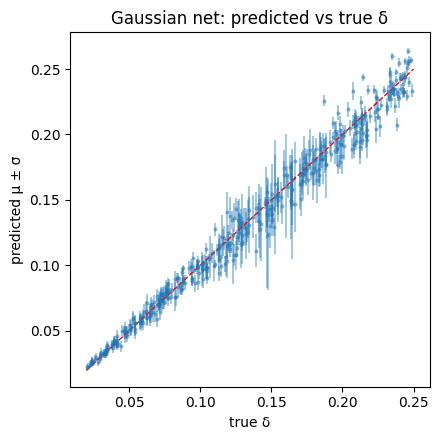

In [17]:
model.eval()
with torch.no_grad():
    mu_te, sigma_te = model(Xte)

rmse     = ((mu_te - yte)**2).mean().sqrt().item()
test_nll = gaussian_nll(mu_te, sigma_te, yte).item()
print(f"test RMSE {rmse:.4f}   (δ spans 0.02–0.25, range 0.23)")
print(f"test NLL  {test_nll:.4f}")

plt.figure(figsize=(4.5, 4.5))
plt.errorbar(yte.numpy().ravel(), mu_te.numpy().ravel(),
             yerr=sigma_te.numpy().ravel(), fmt='.', alpha=0.4, ms=4)
plt.plot([0.02, 0.25], [0.02, 0.25], 'r--', lw=1)   # perfect-prediction line
plt.xlabel("true δ"); plt.ylabel("predicted μ ± σ")
plt.title("Gaussian net: predicted vs true δ")
plt.tight_layout(); plt.show()


In [18]:
model.eval()
with torch.no_grad():
    mu_te, sigma_te = model(Xte)

z    = ((yte - mu_te) / sigma_te).abs()     # how many σ the true δ sits from μ
cov1 = (z <= 1).float().mean().item()       # fraction inside ±1σ
cov2 = (z <= 2).float().mean().item()       # fraction inside ±2σ
print(f"within ±1σ: {cov1:.1%}   (ideal 68%)")
print(f"within ±2σ: {cov2:.1%}   (ideal 95%)")


within ±1σ: 65.5%   (ideal 68%)
within ±2σ: 88.0%   (ideal 95%)
